In [1]:
import os, random, time, itertools, numpy as np, pandas as pd, torch, torch.nn as nn
from collections import Counter
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print(dev)
def seed_all(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

CSV = next((p for p in ["dataset_education.csv", "/kaggle/input/datasets/laghrissimehdi/dataset-education/dataset_education.csv"] if os.path.exists(p)), None)
assert CSV, "fix the CSV path"
df = pd.read_csv(CSV)
TEXT_COL = "stems"     # try "tokens" / "lemmas" as an ablation
df = df[df[TEXT_COL].notna()].reset_index(drop=True)
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
print(len(tr), len(va), len(te))

cuda
301 63 86


In [2]:
MAXLEN, MIN_FREQ = 256, 2
cnt = Counter(w for t in tr[TEXT_COL] for w in t.split())
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}; V = len(itos); print("vocab:", V)
encode = lambda t: ([stoi.get(w, 1) for w in t.split()][:MAXLEN] or [1])

class DS(torch.utils.data.Dataset):
    def __init__(self, d): self.x = [encode(t) for t in d[TEXT_COL]]; self.y = d["label"].tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]
def collate(b):
    xs, ys = zip(*b); L = torch.tensor([len(x) for x in xs])
    X = torch.zeros(len(xs), int(L.max()), dtype=torch.long)
    for i, x in enumerate(xs): X[i, :len(x)] = torch.tensor(x)
    return X, L, torch.tensor(ys)
def loaders(bs):
    mk = lambda d, sh: torch.utils.data.DataLoader(DS(d), batch_size=bs, shuffle=sh, collate_fn=collate)
    return mk(tr, True), mk(va, False), mk(te, False)

vocab: 3647


In [5]:
class Net(nn.Module):
    def __init__(self, kind, bi, V, emb=128, hid=128, layers=1, drop=0.3, n_cls=3):
        super().__init__()
        self.emb = nn.Embedding(V, emb, padding_idx=0)
        rnn = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[kind]
        kw = dict(nonlinearity="tanh") if kind == "rnn" else {}
        self.rnn = rnn(emb, hid, num_layers=layers, batch_first=True, bidirectional=bi,
                       dropout=drop if layers > 1 else 0, **kw)
        self.drop = nn.Dropout(drop); self.fc = nn.Linear(hid * (2 if bi else 1), n_cls)
    def forward(self, x, L):
        e = self.drop(self.emb(x))
        out, _ = self.rnn(pack_padded_sequence(e, L.cpu(), batch_first=True, enforce_sorted=False))
        out, _ = pad_packed_sequence(out, batch_first=True)
        mask = (torch.arange(out.size(1), device=out.device)[None, :] < L.to(out.device)[:, None]).unsqueeze(-1)
        return self.fc(self.drop(out.masked_fill(~mask, -1e9).max(1).values))

ARCHS = {"RNN": ("rnn", False), "BiRNN": ("rnn", True), "GRU": ("gru", False), "LSTM": ("lstm", False)}

In [6]:
cw = torch.tensor(len(tr) / (3 * np.bincount(tr["label"], minlength=3).clip(1)), dtype=torch.float).to(dev)

@torch.no_grad()
def predict(m, dl):
    m.eval(); P, Y = [], []
    for X, L, y in dl: P += m(X.to(dev), L).argmax(1).cpu().tolist(); Y += y.tolist()
    return np.array(Y), np.array(P)

def fit(kind, bi, cfg, seed, epochs=40, patience=6):
    seed_all(seed); trl, val, tel = loaders(cfg["bs"])
    m = Net(kind, bi, V, cfg["emb"], cfg["hid"], cfg["layers"], cfg["drop"]).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    lossf = nn.CrossEntropyLoss(weight=cw); best, state, bad = -1, None, 0
    for ep in range(epochs):
        m.train()
        for X, L, y in trl:
            opt.zero_grad(); lossf(m(X.to(dev), L), y.to(dev)).backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        yv, pv = predict(m, val); f1 = f1_score(yv, pv, average="macro")
        if f1 > best: best, bad, state = f1, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(state); return m, best, tel

SPACE = dict(emb=[64,128,200], hid=[64,128,256], layers=[1,2], drop=[0.2,0.3,0.5],
             lr=[1e-3,5e-4,3e-4], wd=[0,1e-2], bs=[16,32])
def sample_cfgs(n, seed=0):
    rng = random.Random(seed); return [{k: rng.choice(v) for k, v in SPACE.items()} for _ in range(n)]

In [7]:
N_TRIALS = 8
cfgs, search = sample_cfgs(N_TRIALS), []
for name, (kind, bi) in ARCHS.items():
    for i, cfg in enumerate(cfgs):
        t0 = time.time(); _, f1, _ = fit(kind, bi, cfg, seed=0)
        search.append(dict(model=name, trial=i, val_f1=f1, **cfg))
        print(f"{name:6s} #{i} valF1 {f1:.3f} ({time.time()-t0:.0f}s) {cfg}")
S = pd.DataFrame(search); S.to_csv("hparam_search.csv", index=False)
cast = lambda k, v: int(v) if k in ("emb","hid","layers","bs") else float(v)
best_cfg = {n: {k: cast(k, S[S.model == n].sort_values("val_f1", ascending=False).iloc[0][k]) for k in SPACE} for n in ARCHS}
print(pd.DataFrame(best_cfg).T)

RNN    #0 valF1 0.632 (11s) {'emb': 128, 'hid': 128, 'layers': 1, 'drop': 0.3, 'lr': 0.0003, 'wd': 0.01, 'bs': 32}
RNN    #1 valF1 0.557 (5s) {'emb': 128, 'hid': 128, 'layers': 2, 'drop': 0.5, 'lr': 0.001, 'wd': 0, 'bs': 32}
RNN    #2 valF1 0.302 (3s) {'emb': 64, 'hid': 64, 'layers': 2, 'drop': 0.5, 'lr': 0.0003, 'wd': 0, 'bs': 32}
RNN    #3 valF1 0.600 (4s) {'emb': 64, 'hid': 256, 'layers': 1, 'drop': 0.5, 'lr': 0.0005, 'wd': 0.01, 'bs': 16}
RNN    #4 valF1 0.379 (2s) {'emb': 128, 'hid': 128, 'layers': 2, 'drop': 0.5, 'lr': 0.0003, 'wd': 0, 'bs': 32}
RNN    #5 valF1 0.707 (5s) {'emb': 128, 'hid': 256, 'layers': 2, 'drop': 0.2, 'lr': 0.0003, 'wd': 0, 'bs': 16}
RNN    #6 valF1 0.512 (4s) {'emb': 200, 'hid': 128, 'layers': 1, 'drop': 0.5, 'lr': 0.0005, 'wd': 0.01, 'bs': 16}
RNN    #7 valF1 0.590 (6s) {'emb': 200, 'hid': 128, 'layers': 1, 'drop': 0.2, 'lr': 0.0003, 'wd': 0, 'bs': 16}
BiRNN  #0 valF1 0.680 (4s) {'emb': 128, 'hid': 128, 'layers': 1, 'drop': 0.3, 'lr': 0.0003, 'wd': 0.01, 'b

In [8]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
def label_bleu(y, p, chunk=10, seed=0):
    idx = np.random.RandomState(seed).permutation(len(y)); y, p = y[idx], p[idx]
    refs = [[[str(v) for v in y[i:i+chunk]]] for i in range(0, len(y)-chunk+1, chunk)]
    hyps = [[str(v) for v in p[i:i+chunk]] for i in range(0, len(y)-chunk+1, chunk)]
    return corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)

SEEDS, results, cms, preds = [0, 1, 2], [], {}, {}
for name, (kind, bi) in ARCHS.items():
    for s in SEEDS:
        m, _, tel = fit(kind, bi, best_cfg[name], seed=s); y, p = predict(m, tel)
        results.append(dict(model=name, seed=s, acc=accuracy_score(y, p), f1_macro=f1_score(y, p, average="macro"),
                            f1_weighted=f1_score(y, p, average="weighted"), mae=np.abs(y-p).mean(), bleu=label_bleu(y, p)))
        cms[(name, s)] = confusion_matrix(y, p, labels=[0,1,2]); preds[(name, s)] = (y, p)
R = pd.DataFrame(results); R.to_csv("results_runs.csv", index=False)
summary = R.groupby("model")[["acc","f1_macro","f1_weighted","mae","bleu"]].agg(["mean","std"]).round(3)
summary.to_csv("results_summary.csv"); summary

acc        f1_macro        f1_weighted           mae          bleu  \
        mean    std     mean    std        mean    std   mean    std   mean   
model                                                                         
BiRNN  0.655  0.029    0.604  0.040       0.644  0.033  0.372  0.042  0.443   
GRU    0.609  0.041    0.589  0.047       0.612  0.039  0.407  0.065  0.414   
LSTM   0.624  0.029    0.593  0.019       0.623  0.021  0.407  0.035  0.387   
RNN    0.628  0.071    0.583  0.064       0.611  0.066  0.407  0.081  0.373   

              
         std  
model         
BiRNN  0.047  
GRU    0.053  
LSTM   0.031  
RNN    0.012

TF-IDF + LogReg: {'acc': 0.628, 'f1_macro': 0.623, 'mae': np.float64(0.372), 'bleu': 0.405}


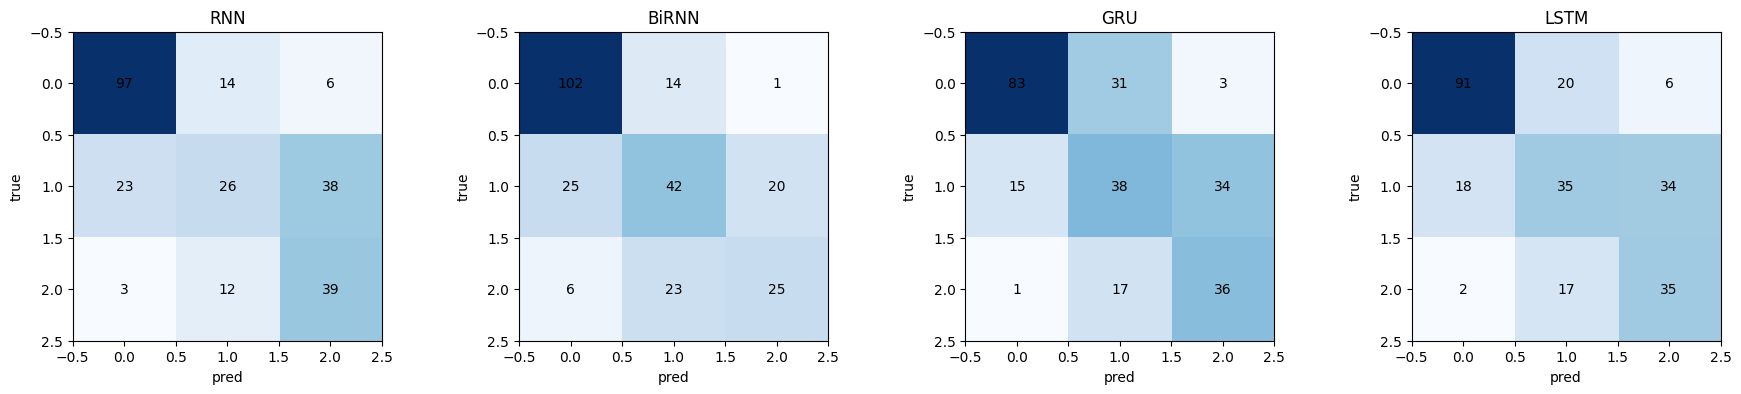

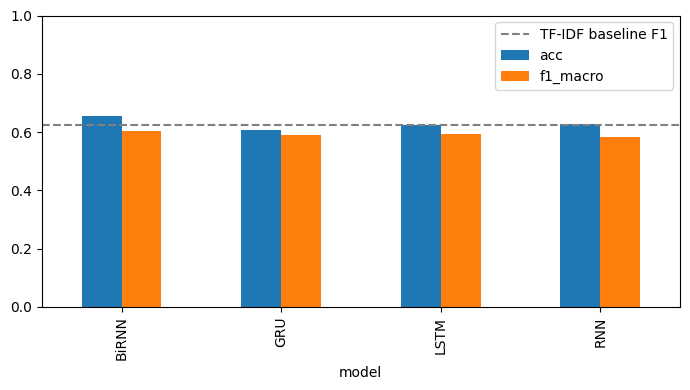

               precision    recall  f1-score   support

 not relevant       0.82      0.85      0.84        39
       medium       0.52      0.41      0.46        29
very relevant       0.48      0.61      0.54        18

     accuracy                           0.65        86
    macro avg       0.61      0.62      0.61        86
 weighted avg       0.65      0.65      0.65        86



In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
tf = TfidfVectorizer(min_df=2, ngram_range=(1,2), sublinear_tf=True)
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(tf.fit_transform(tr[TEXT_COL]), tr["label"])
pb, yb = lr.predict(tf.transform(te[TEXT_COL])), te["label"].values
base = dict(acc=accuracy_score(yb,pb), f1_macro=f1_score(yb,pb,average="macro"), mae=np.abs(yb-pb).mean(), bleu=label_bleu(yb,pb))
print("TF-IDF + LogReg:", {k: round(v,3) for k,v in base.items()})

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, name in zip(ax, ARCHS):
    cm = sum(cms[(name, s)] for s in SEEDS); a.imshow(cm, cmap="Blues"); a.set_title(name)
    for i, j in itertools.product(range(3), range(3)): a.text(j, i, cm[i,j], ha="center", va="center")
    a.set_xlabel("pred"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

R.groupby("model")[["acc","f1_macro"]].mean().plot.bar(figsize=(7,4), ylim=(0,1))
plt.axhline(base["f1_macro"], ls="--", c="gray", label="TF-IDF baseline F1"); plt.legend()
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()
y, p = preds[("LSTM", 0)]; print(classification_report(y, p, target_names=["not relevant","medium","very relevant"]))